   Sales  CompPrice  Income  Advertising  Population  Price ShelveLoc  Age  \
0   9.50        138      73           11         276    120       Bad   42   
1  11.22        111      48           16         260     83      Good   65   
2  10.06        113      35           10         269     80    Medium   59   
3   7.40        117     100            4         466     97    Medium   55   
4   4.15        141      64            3         340    128       Bad   38   

   Education Urban   US  
0         17   Yes  Yes  
1         10   Yes  Yes  
2         12   Yes  Yes  
3         14   Yes  Yes  
4         13   Yes   No  
               coef  std err       t  P>|t|
intercept   13.0435    0.651  20.036  0.000
Price       -0.0545    0.005 -10.389  0.000
Urban[Yes]  -0.0219    0.272  -0.081  0.936
US[Yes]      1.2006    0.259   4.635  0.000
=== ANOVA TABLE ===
             df       sum_sq     mean_sq           F        PR(>F)
Urban       1.0     0.756615    0.756615    0.123767  7.251713e-01
U

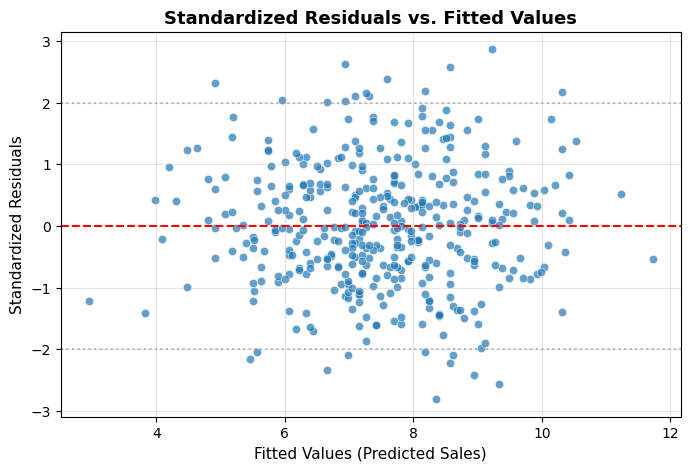

In [14]:

!pip install ISLP

from ISLP import load_data
import statsmodels.api as sm
from ISLP.models import ModelSpec as MS, summarize

# Load the dataset using your exact command
Carseats = load_data('Carseats')

# Confirm it loaded properly by viewing the first 5 rows
print(Carseats.head())



import pandas as pd
import numpy as np
import statsmodels.api as sm
import matplotlib.pyplot as plt
from ISLP import load_data
from ISLP.models import ModelSpec as MS, summarize

# 1. Load the Carseats dataset
Carseats = load_data('Carseats')

# 2. Set up target (y) and predictors (X) using ModelSpec
y = Carseats['Sales']
design = MS(['Price', 'Urban', 'US'])
X = design.fit_transform(Carseats)

# 3. Fit the OLS regression model
model = sm.OLS(y, X)
results = model.fit()

# 4. View the clean summary statistics
print(summarize(results))


import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# 1. Fit the model using a standard text formula string
formula_model = smf.ols('Sales ~ Price + Urban + US', data=Carseats).fit()

# 2. Run the ANOVA table directly
print("=== ANOVA TABLE ===")
print(anova_lm(formula_model))

print(results.summary())

# Repeat after having removed Urban
print("Removed Urban:")
design = MS(['Price', 'US'])
X = design.fit_transform(Carseats)

# 3. Fit the OLS regression model
model = sm.OLS(y, X)
results = model.fit()

# 4. View the clean summary statistics
print(summarize(results))



# 1. Fit the model using a standard text formula string
formula_model = smf.ols('Sales ~ Price + US', data=Carseats).fit()

# 2. Run the ANOVA table directly
print("=== ANOVA TABLE ===")
print(anova_lm(formula_model))

print(results.summary())




import matplotlib.pyplot as plt
import seaborn as sns

# 1. Extract fitted values and calculate standardized residuals
fitted_values = results.fittedvalues
# .get_influence() extracts the advanced diagnostic metrics from statsmodels
standardized_residuals = results.get_influence().resid_studentized_internal

# 2. Create the plot
plt.figure(figsize=(8, 5))
sns.scatterplot(x=fitted_values, y=standardized_residuals, alpha=0.7)

# 3. Add a horizontal line at 0 (where perfect predictions would land)
plt.axhline(y=0, color='red', linestyle='--', linewidth=1.5)

# 4. Add safety thresholds at +2 and -2 (standard outlier thresholds)
plt.axhline(y=2, color='gray', linestyle=':', alpha=0.5)
plt.axhline(y=-2, color='gray', linestyle=':', alpha=0.5)

# 5. Label the graph
plt.xlabel("Fitted Values (Predicted Sales)", fontsize=11)
plt.ylabel("Standardized Residuals", fontsize=11)
plt.title("Standardized Residuals vs. Fitted Values", fontsize=13, fontweight='bold')
plt.grid(True, alpha=0.3)

# Display the plot
plt.show()

